[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sensioai/blog/blob/master/044_cnn_transfer_learning/cnn_transfer_learning.ipynb)

# Transfer Learning en Redes Convolucionales

En posts anteriores hemos introducido la arquitectura de `red neuronal convolucional` y también hemos presentado varias arquitecturas famosas que han demostrado buenas prestaciones en multitud de tareas. Estas redes están formadas muchas capas convolucionales, algunas con más de 100 capas, lo cual significa que tienen muchos parámetros y entrenarlas desde cero puedes ser costoso. Sin embargo, existe una técnica que nos permite obtener buenos modelos con menores requisitos: el *transfer learning*. Ya hemos hablado anteriormente de esta técnica, en el contexto de modelos de lenguaje, pero la idea es la misma: utilizaremos el máximo número de capas de una red ya entrenada en otro dataset, y simplemente entrenaremos las nuevas capas que necesitemos para nuestra tarea concreta.

![](https://pennylane.ai/qml/_images/transfer_learning_general.png)

En este post vamos a ver cómo podemos utilizar una red neuronal pre-entrada en Imagenet, y adaptarla para una nueva tarea de clasificación con un pequeño dataset.

## El dataset

Nuestro objetivo será el de entrenar un clasificador de flores. Podemos descargar las imágenes de la siguiente url.

In [1]:
!pip install wget

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=a54f84df517f7821af9f2aac9f0270c9648c25a51bcd39af3cd59f6ee16da824
  Stored in directory: /root/.cache/pip/wheels/40/b3/0f/a40dbd1c6861731779f62cc4babcb234387e11d697df70ee97
Successfully built wget


In [2]:
import wget

wget.download('https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/flowers.zip')

'flowers.zip'

In [3]:
import zipfile

with zipfile.ZipFile('flowers.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

Una vez extraído el dataset, podemos ver que tenemos 5 clases de flores diferentes, distribuidas en 5 carpetas diferentes. Cada carpeta contiene varios ejemplos de flores de la categoría en cuestión.

In [4]:
import os

PATH = 'flowers'

classes = os.listdir(PATH)
classes

['rose', 'dandelion', 'daisy', 'sunflower', 'tulip']

In [5]:
imgs, labels = [], []

for i, lab in enumerate(classes):
  paths = os.listdir(f'{PATH}/{lab}')
  print(f'Categoría: {lab}. Imágenes: {len(paths)}')
  paths = [p for p in paths if p[-3:] == "jpg"]
  imgs += [f'{PATH}/{lab}/{img}' for img in paths]
  labels += [i]*len(paths)

Categoría: rose. Imágenes: 784
Categoría: dandelion. Imágenes: 1055
Categoría: daisy. Imágenes: 769
Categoría: sunflower. Imágenes: 734
Categoría: tulip. Imágenes: 984


In [6]:
imgs[:5]
len(imgs)

4323

Podemos visualizar algunas imágenes en el dataset.

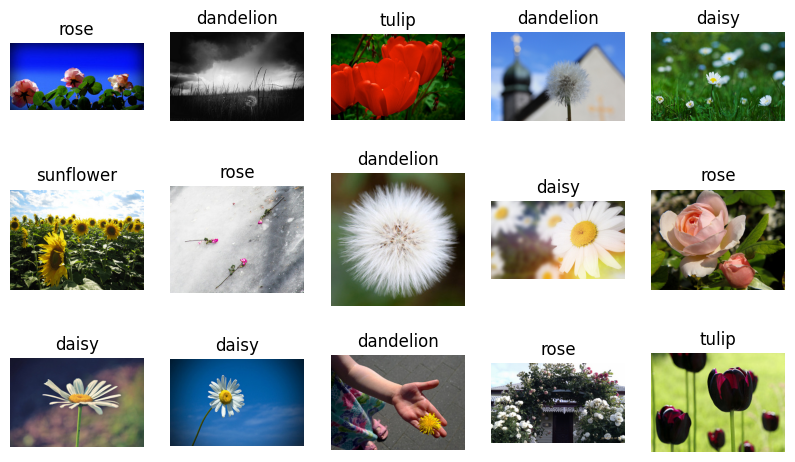

In [7]:
import random
from skimage import io
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3,5, figsize=(10,6))
for _ax in axs:
  for ax in _ax:
    ix = random.randint(0, len(imgs)-1)
    img = io.imread(imgs[ix])
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(classes[labels[ix]])
plt.show()

Vamos a crear también un subconjunto de test para poder comparar varios modelos.

In [8]:
from sklearn.model_selection import train_test_split

train_imgs, test_imgs, train_labels, test_labels = train_test_split(imgs, labels, test_size=0.2, stratify=labels)

len(train_imgs), len(test_imgs)

(3458, 865)

Y por último creamos nuestros objetos `Dataset` y `DataLoader` para poder darle las imágenes a nuestros modelos.

In [9]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

class Dataset(torch.utils.data.Dataset):
  def __init__(self, X, y, trans, device):
    self.X = X
    self.y = y
    self.trans = trans
    self.device = device

  def __len__(self):
    return len(self.X)

  def __getitem__(self, ix):
    # cargar la imágen
    img = io.imread(self.X[ix])
    # aplicar transformaciones
    #print(f"imagen: {img}")
    if self.trans:
      img = self.trans(image=img)["image"]
    return torch.from_numpy(img / 255.).float().permute(2,0,1), torch.tensor(self.y[ix])

Nos aseguraremos que todas las imágenes del dataset tengan las mismas dimensiones: 224x224 píxeles.

In [10]:
import albumentations as A

trans = A.Compose([
    A.Resize(224, 224)
])

dataset = {
    'train': Dataset(train_imgs, train_labels, trans, device),
    'test': Dataset(test_imgs, test_labels, trans, device)
}

len(dataset['train']), len(dataset['test'])

(3458, 865)

In [11]:
dataset['train'][2]

(tensor([[[0.0275, 0.0275, 0.0275,  ..., 0.7608, 0.7529, 0.7569],
          [0.0275, 0.0275, 0.0275,  ..., 0.7529, 0.7569, 0.7569],
          [0.0275, 0.0275, 0.0275,  ..., 0.7490, 0.7569, 0.7529],
          ...,
          [0.0353, 0.0314, 0.0353,  ..., 0.0353, 0.0392, 0.0353],
          [0.0275, 0.0275, 0.0314,  ..., 0.0353, 0.0314, 0.0314],
          [0.0275, 0.0235, 0.0275,  ..., 0.0392, 0.0314, 0.0353]],
 
         [[0.0275, 0.0275, 0.0275,  ..., 0.1137, 0.1098, 0.1098],
          [0.0275, 0.0275, 0.0275,  ..., 0.1098, 0.1098, 0.1098],
          [0.0275, 0.0275, 0.0275,  ..., 0.1176, 0.1098, 0.1098],
          ...,
          [0.0392, 0.0314, 0.0353,  ..., 0.0431, 0.0431, 0.0392],
          [0.0314, 0.0275, 0.0314,  ..., 0.0392, 0.0392, 0.0392],
          [0.0275, 0.0235, 0.0275,  ..., 0.0431, 0.0431, 0.0431]],
 
         [[0.0275, 0.0275, 0.0275,  ..., 0.0039, 0.0000, 0.0000],
          [0.0275, 0.0275, 0.0275,  ..., 0.0000, 0.0000, 0.0000],
          [0.0275, 0.0275, 0.0275,  ...,

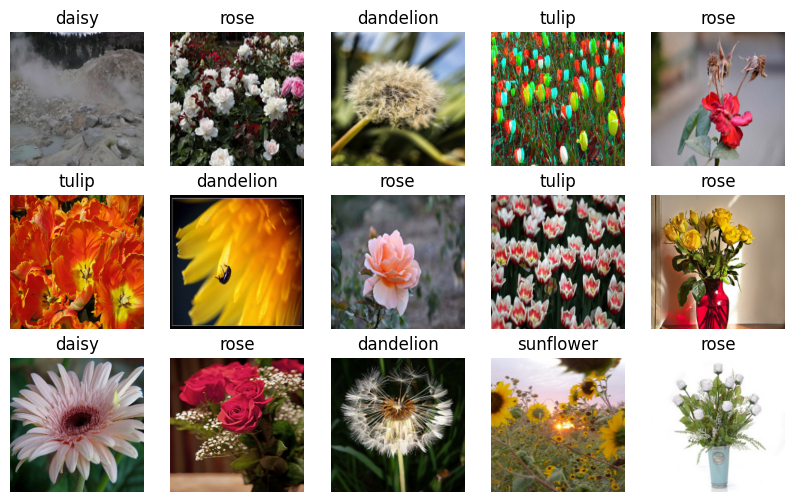

In [12]:
fig, axs = plt.subplots(3,5, figsize=(10,6))
for _ax in axs:
  for ax in _ax:
    ix = random.randint(0, len(dataset['train'])-1)
    img, lab = dataset['train'][ix]
    ax.imshow(img.permute(1,2,0))
    ax.axis('off')
    ax.set_title(classes[lab])
plt.show()

In [13]:
dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=64, shuffle=True, pin_memory=True),
    'test': torch.utils.data.DataLoader(dataset['test'], batch_size=256, shuffle=False)
}

imgs, labels = next(iter(dataloader['train']))
imgs.shape

torch.Size([64, 3, 224, 224])

## El Modelo

Vamos a escoger la arquitectura `resnet`, de la que ya hablamos en el post anterior, para hacer nuestro clasificador. De este modelo usarmos todas las capas excepto la última, la cual sustituiremos por una nueva capa lineal para llevar a cabo la clasificación en 5 clases.

In [14]:
import torchvision

resnet = torchvision.models.resnet18()
resnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [15]:
class ModelCustom(torch.nn.Module):
  def __init__(self, n_outputs=5, pretrained=False, freeze=False):
    super().__init__()
    # descargamos resnet
    resnet = torchvision.models.resnet18(pretrained=pretrained)
    # nos quedamos con todas las capas menos la última
    self.resnet = torch.nn.Sequential(*list(resnet.children())[:-1])
    if freeze:
      for param in self.resnet.parameters():
        param.requires_grad=False
    # añadimos una nueva capa lineal para llevar a cabo la clasificación
    self.fc = torch.nn.Linear(512, 5)

  def forward(self, x):
    x = self.resnet(x)
    x = x.view(x.shape[0], -1)
    x = self.fc(x)
    return x

  def unfreeze(self):
    for param in self.resnet.parameters():
        param.requires_grad=True

In [16]:
model_custom = ModelCustom()
outputs = model_custom(torch.randn(64, 3, 224, 224))
outputs.shape

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


torch.Size([64, 5])

In [17]:
from tqdm import tqdm
import numpy as np

def fit(model, dataloader, epochs=5, lr=1e-2):
    model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    criterion = torch.nn.CrossEntropyLoss()
    for epoch in range(1, epochs+1):
        model.train()
        train_loss, train_acc = [], []
        bar = tqdm(dataloader['train'])
        for batch in bar:
            X, y = batch
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            y_hat = model(X)
            loss = criterion(y_hat, y)
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())
            acc = (y == torch.argmax(y_hat, axis=1)).sum().item() / len(y)
            train_acc.append(acc)
            bar.set_description(f"loss {np.mean(train_loss):.5f} acc {np.mean(train_acc):.5f}")
        bar = tqdm(dataloader['test'])
        val_loss, val_acc = [], []
        model.eval()
        with torch.no_grad():
            for batch in bar:
                X, y = batch
                X, y = X.to(device), y.to(device)
                y_hat = model(X)
                loss = criterion(y_hat, y)
                val_loss.append(loss.item())
                acc = (y == torch.argmax(y_hat, axis=1)).sum().item() / len(y)
                val_acc.append(acc)
                bar.set_description(f"val_loss {np.mean(val_loss):.5f} val_acc {np.mean(val_acc):.5f}")
        print(f"Epoch {epoch}/{epochs} loss {np.mean(train_loss):.5f} val_loss {np.mean(val_loss):.5f} acc {np.mean(train_acc):.5f} val_acc {np.mean(val_acc):.5f}")

### Entrenando desde cero

En primer lugar vamos a entrenar nuestro modelo desde cero para ver qué métricas podemos obtener.

In [18]:
model_c = ModelCustom()
fit(model_c, dataloader, epochs=15)

val_loss 3.24421 val_acc 0.18026: 100%|██████████| 4/4 [00:03<00:00,  1.12it/s]


Epoch 1/15 loss 1.33118 val_loss 3.24421 acc 0.44602 val_acc 0.18026


val_loss 3.98305 val_acc 0.21197: 100%|██████████| 4/4 [00:03<00:00,  1.25it/s]


Epoch 2/15 loss 1.14304 val_loss 3.98305 acc 0.53438 val_acc 0.21197


val_loss 2.30493 val_acc 0.36044: 100%|██████████| 4/4 [00:03<00:00,  1.11it/s]


Epoch 3/15 loss 1.01622 val_loss 2.30493 acc 0.58892 val_acc 0.36044


... (20 outputs left out)

val_loss 3.17628 val_acc 0.41185: 100%|██████████| 4/4 [00:03<00:00,  1.25it/s]


Epoch 14/15 loss 0.57686 val_loss 3.17628 acc 0.79716 val_acc 0.41185


val_loss 2.54885 val_acc 0.42208: 100%|██████████| 4/4 [00:03<00:00,  1.26it/s]

Epoch 15/15 loss 0.53164 val_loss 2.54885 acc 0.81392 val_acc 0.42208


Como puedes ver es complicado conseguir buenas métricas ya que nuestro dataset es muy pequeño.

## Transfer Learning

Ahora vamos a entrenar el mismo caso pero, en este caso, utilizando los pesos pre-entrenados de `resnet`.

In [19]:
model_c = ModelCustom(pretrained=True, freeze=True)
fit(model_c, dataloader)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]
val_loss 1.07095 val_acc 0.53910: 100%|██████████| 4/4 [00:03<00:00,  1.08it/s]


Epoch 1/5 loss 1.10689 val_loss 1.07095 acc 0.61023 val_acc 0.53910


val_loss 0.72536 val_acc 0.71885: 100%|██████████| 4/4 [00:03<00:00,  1.18it/s]


Epoch 2/5 loss 0.65520 val_loss 0.72536 acc 0.80483 val_acc 0.71885


val_loss 0.60338 val_acc 0.77463: 100%|██████████| 4/4 [00:03<00:00,  1.18it/s]


Epoch 3/5 loss 0.53700 val_loss 0.60338 acc 0.83437 val_acc 0.77463


val_loss 0.60528 val_acc 0.77994: 100%|██████████| 4/4 [00:03<00:00,  1.17it/s]


Epoch 4/5 loss 0.48054 val_loss 0.60528 acc 0.84432 val_acc 0.77994


val_loss 0.50533 val_acc 0.82337: 100%|██████████| 4/4 [00:03<00:00,  1.22it/s]

Epoch 5/5 loss 0.44443 val_loss 0.50533 acc 0.86364 val_acc 0.82337


Como puedes ver no sólo obtenemos un mejor modelo en menos *epochs* sino que además cada *epoch* tarda menos en completarse. Esto es debido a que, al no estar entrenando gran parte de la red, los requisitos computacionales se reducen considerablemente. Mejores modelos y entrenados más rápido.

## Fine Tuning

Todavía podemos mejorar un poco más si, además de utilizar los pesos descargados de Imagenet en `resnet`, entrenamos también la red completa.

In [20]:
model_c = ModelCustom(pretrained=True, freeze=False)
fit(model_c, dataloader)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
val_loss 0.48781 val_acc 0.83279: 100%|██████████| 4/4 [00:03<00:00,  1.23it/s]


Epoch 1/5 loss 0.79993 val_loss 0.48781 acc 0.73466 val_acc 0.83279


val_loss 0.40870 val_acc 0.86165: 100%|██████████| 4/4 [00:03<00:00,  1.24it/s]


Epoch 2/5 loss 0.35848 val_loss 0.40870 acc 0.89659 val_acc 0.86165


val_loss 0.37421 val_acc 0.87052: 100%|██████████| 4/4 [00:03<00:00,  1.22it/s]


Epoch 3/5 loss 0.25584 val_loss 0.37421 acc 0.92727 val_acc 0.87052


val_loss 0.36460 val_acc 0.86973: 100%|██████████| 4/4 [00:03<00:00,  1.14it/s]


Epoch 4/5 loss 0.19616 val_loss 0.36460 acc 0.94318 val_acc 0.86973


val_loss 0.28581 val_acc 0.89993: 100%|██████████| 4/4 [00:03<00:00,  1.07it/s]

Epoch 5/5 loss 0.13967 val_loss 0.28581 acc 0.96449 val_acc 0.89993


Es común entrenar primero el modelo sin entrenar la red pre-entrenada durante varias epochs y después seguir entrenando, pero permitiendo ahora la actualización de pesos también en la red pre-entrenada (usualmente con un *learning rate* más pequeño).

In [21]:
model_o = ModelCustom(pretrained=True, freeze=True)
fit(model_o, dataloader)
model_o.unfreeze()
fit(model_o, dataloader, lr=1e-4)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
val_loss 1.02152 val_acc 0.58503: 100%|██████████| 4/4 [00:03<00:00,  1.22it/s]


Epoch 1/5 loss 1.04445 val_loss 1.02152 acc 0.65227 val_acc 0.58503


val_loss 0.87771 val_acc 0.62597: 100%|██████████| 4/4 [00:03<00:00,  1.12it/s]


Epoch 2/5 loss 0.65046 val_loss 0.87771 acc 0.80966 val_acc 0.62597


val_loss 1.53571 val_acc 0.41711: 100%|██████████| 4/4 [00:03<00:00,  1.20it/s]


Epoch 3/5 loss 0.55377 val_loss 1.53571 acc 0.83466 val_acc 0.41711


... (10 outputs left out)

val_loss 0.47954 val_acc 0.82693: 100%|██████████| 4/4 [00:03<00:00,  1.02it/s]


Epoch 4/5 loss 0.45836 val_loss 0.47954 acc 0.83523 val_acc 0.82693


val_loss 0.46246 val_acc 0.84185: 100%|██████████| 4/4 [00:03<00:00,  1.24it/s]

Epoch 5/5 loss 0.42575 val_loss 0.46246 acc 0.86733 val_acc 0.84185


Otra alternativa de *fine tuning* es la de entrenar el modelo con diferentes *learning rates*, uno para la red pre-entrenada y otro para las capas nuevas.

In [22]:
optimizer = torch.optim.Adam([
    {'params': model_o.resnet.parameters(), 'lr': 1e-4},
    {'params': model_o.fc.parameters(), 'lr': 1e-3}
])

In [23]:
from tqdm import tqdm
import numpy as np

def fit(model, dataloader, epochs=5, lr_resnet=1e-4, lr_fc=1e-3):
    model.to(device)
    optimizer = optimizer = torch.optim.Adam([{'params': model.resnet.parameters(), 'lr': lr_resnet},{'params': model.fc.parameters(), 'lr': lr_fc}])
    criterion = torch.nn.CrossEntropyLoss()
    for epoch in range(1, epochs+1):
        model.train()
        train_loss, train_acc = [], []
        bar = tqdm(dataloader['train'])
        for batch in bar:
            X, y = batch
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            y_hat = model(X)
            loss = criterion(y_hat, y)
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())
            acc = (y == torch.argmax(y_hat, axis=1)).sum().item() / len(y)
            train_acc.append(acc)
            bar.set_description(f"loss {np.mean(train_loss):.5f} acc {np.mean(train_acc):.5f}")
        bar = tqdm(dataloader['test'])
        val_loss, val_acc = [], []
        model.eval()
        with torch.no_grad():
            for batch in bar:
                X, y = batch
                X, y = X.to(device), y.to(device)
                y_hat = model(X)
                loss = criterion(y_hat, y)
                val_loss.append(loss.item())
                acc = (y == torch.argmax(y_hat, axis=1)).sum().item() / len(y)
                val_acc.append(acc)
                bar.set_description(f"val_loss {np.mean(val_loss):.5f} val_acc {np.mean(val_acc):.5f}")
        print(f"Epoch {epoch}/{epochs} loss {np.mean(train_loss):.5f} val_loss {np.mean(val_loss):.5f} acc {np.mean(train_acc):.5f} val_acc {np.mean(val_acc):.5f}")

In [ ]:
model_o = ModelCustom(pretrained=True, freeze=True)
fit(model_o, dataloader, lr_resnet=1e-4, lr_fc=1e-3)
model_o.unfreeze()
fit(model_o, dataloader, lr_resnet=1e-4, lr_fc=1e-3)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
val_loss 0.63166 val_acc 0.80322: 100%|██████████| 4/4 [00:03<00:00,  1.02it/s]


Epoch 1/5 loss 0.98523 val_loss 0.63166 acc 0.66108 val_acc 0.80322


val_loss 0.52298 val_acc 0.82603: 100%|██████████| 4/4 [00:03<00:00,  1.17it/s]


Epoch 2/5 loss 0.57107 val_loss 0.52298 acc 0.80966 val_acc 0.82603


val_loss 0.45964 val_acc 0.85197: 100%|██████████| 4/4 [00:03<00:00,  1.21it/s]


Epoch 3/5 loss 0.49678 val_loss 0.45964 acc 0.82784 val_acc 0.85197


... (10 outputs left out)

val_loss 0.22600 val_acc 0.93145: 100%|██████████| 4/4 [00:03<00:00,  1.23it/s]


Epoch 4/5 loss 0.01395 val_loss 0.22600 acc 0.99801 val_acc 0.93145


val_loss 0.33043 val_acc 0.91520: 100%|██████████| 4/4 [00:03<00:00,  1.23it/s]

Epoch 5/5 loss 0.04457 val_loss 0.33043 acc 0.97642 val_acc 0.91520


## Resumen

En este post hemos visto como podemos llevar a cabo *transfer learning* con redes convolucionales. Aplicar esta técnica nos permitirá obtener mejores modelos con menos requisitos computacionales y con datasets reducidos. Podemos descargar una red pre-entrenada con otro dataset (idealmente, un dataset similar al nuestro) y aprovechar el máximo número de capas. Podemos *congelar* la red pre-entrenada, de manera que no se actualicen sus pesos durante el entrenamiento, y utilizarla solo como extractor de características que las nuevas capas (las cuales si entrenamos) pueden aprovechar. Aún así, hacer *fine tuning* (seguir entrenando la red pre-entrenada) puede dar como resultado un mejor modelo. El *transfer learning* es una técnica muy potente que siempre que podamos podemos aprovechar para reducir los requisitos computacionales de nuestros modelos.